In [71]:
#pip install scikit-learn

#python -m pip install numpy pandas scikit-learn

%pip install scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Generate 40 random X values (0 to 20) formatted as a 2D array for scikit-learn
X = np.random.uniform(0, 20, size=(40, 1))

# Define a linear relationship with some noise as a function of the random X values from above
y = 3 * X.flatten() + 50 + np.random.normal(0, 10, size=(40,))

# Create a DataFrame to view the dataset
df = pd.DataFrame({'X': X.flatten(), 'Y': y})
display(df.head(40))

Note: you may need to restart the kernel to use updated packages.


,X,Y
0,16.289517,86.248008
1,3.121107,67.268748
2,6.708674,64.290405
3,2.062114,67.509223
4,0.367122,58.508141
5,6.471326,73.886057
6,13.987590,92.549094
7,8.395587,86.056922
8,5.958862,49.843168
9,18.725052,110.500698


In [72]:
# Split the data into training (85%) and testing (15%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42)

# Create and train the Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, max_depth=2, random_state=42)
rf_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = rf_model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"r² Score: {r2:.2f}")

Mean Squared Error: 108.26
r² Score: 0.76


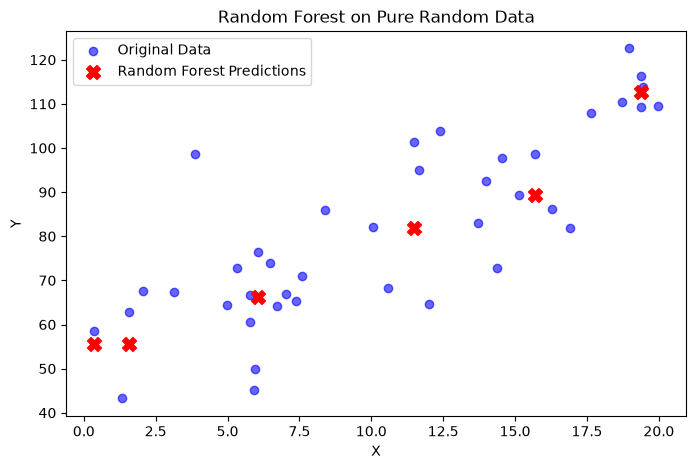

In [73]:
# Visualize the results
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', alpha=0.6, label='Original Data')
# Sort test points for a cleaner prediction line/plot if desired
sort_idx = X_test.flatten().argsort()
plt.scatter(X_test[sort_idx], y_pred[sort_idx], color='red', marker='X', s=100, label='Random Forest Predictions')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.title('Random Forest on Pure Random Data')
plt.show()

In [79]:
# Since we have a very small dataset, we use an 85/15 split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42)

# Initialize the Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, max_depth=2, random_state=42)

# Train (fit) the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [80]:
# Predict on the test set
y_pred = rf_model.predict(X_test)

# Display predictions vs actual values
results_df = pd.DataFrame({'Actual Y': y_test, 'Predicted Y': y_pred})
display(results_df)

# Evaluate model performance
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print(f"R-squared Score: {r2:.4f}")
print(f"Mean Squared Error: {mse:.4f}")

,Actual Y,Predicted Y
0,101.446063,81.841992
1,98.653233,89.340383
2,62.812013,55.558380
3,116.345160,112.721593
4,58.508141,55.558380
5,76.439045,66.237056


R-squared Score: 0.7598
Mean Squared Error: 108.2626


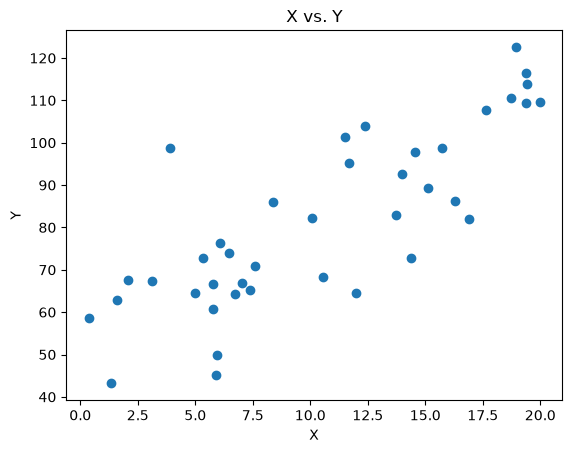

In [82]:
plt.scatter(X, y)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("X vs. Y")

plt.show()

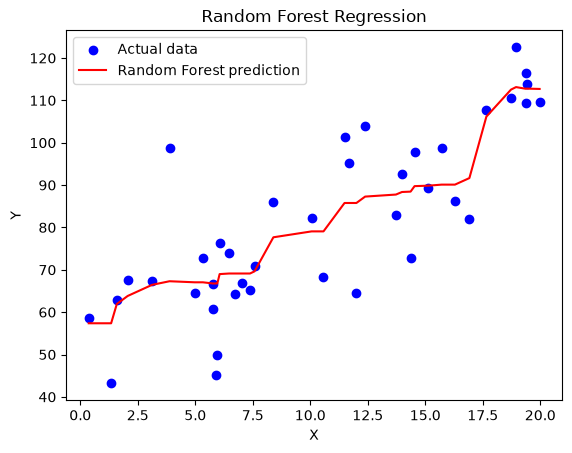

In [84]:
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=2,
    random_state=42
)

model.fit(X, y)

plt.scatter(X, y, color="blue", label="Actual data")

# Sort X so the prediction line doesn't zig-zag
sort_idx = X.flatten().argsort()

plt.plot(
    X.flatten()[sort_idx],
    model.predict(X)[sort_idx],
    color="red",
    label="Random Forest prediction"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Random Forest Regression")
plt.legend()
plt.show()